# Track 1 · Step 5: CNN from scratch (W&B)

AI251P Capstone, Phase 1 (M2: *"a CNN trained from scratch"*, reproducibility). Owner: Abdulmohsen Alharthi.

Input: the Step 4 crops (`01_Data/Processed/Crops/…_Crops{Train,Val,Test}_vN.npy` + `…_CropIndex_vN.csv.gz`).

1. **Config**: one YAML file (`configs/cls_scratch.yaml`), paths relative to `data_root`, logged to W&B as the run config. Until Rayan's repo and W&B project exist, the run goes to your own W&B account (`wandb_entity: null`); later the run can be moved to the team project.
2. **Sanity check**: the model must overfit one fixed batch of 64 crops (train accuracy → 100 %). If it cannot, there is a bug, and the notebook stops before the long run.
3. **Training**: small 4-block CNN, AdamW, warm-up + cosine, label smoothing, class-balanced sampler from Step 4, mixed precision on GPU.
4. **Model selection on val only**: the best epoch by val **macro-F1** is kept (equal weight per class, so rare classes count). **The test split is not used here**; all models are tested once, together, in Step 8.
5. **Logged to W&B**: per-epoch train/val loss and accuracy, val macro-F1, per-class val recall, macro-F1 per domain (sea / urban), learning rate; at the end the val confusion matrix, the config and the checkpoint.

Outputs:
- `02_Classification/Checkpoints/…_cls-scratch_vN.pt` (best epoch, weights + config + class list)
- `02_Classification/…_ValPredictions_cls-scratch_vN.csv.gz` (for the error gallery later)
- `02_Classification/…_Step5Summary_vN.json` (with the W&B run link)

Runtime: **GPU** (Runtime → Change runtime type → T4).

## 0. Install, mount Drive, write the config

In [1]:
!pip -q install wandb pyyaml
from google.colab import drive
drive.mount('/content/drive')
import os; os.makedirs('/content/configs', exist_ok=True)

Mounted at /content/drive


In [2]:
%%writefile /content/configs/cls_scratch.yaml
# Temporary Track 1 config (until the team repo config exists). Paths are relative to data_root.
run:
  name: cls-scratch
  tags: [cls-scratch, track1, phase1]
  wandb_project: ai251p-capstone
  wandb_entity: null          # null = your own W&B account; set to the team entity when Rayan's project exists
seed: 42
data:
  data_root: /content/drive/MyDrive/AI251P_Capstone_CrossDomainAerial
  crops_dir: 01_Data/Processed/Crops
  crops_version: latest       # or e.g. "2026-10-20_v1"
  img_size: 64
  balance_power: 0.5          # sampler weight 1/n_c**p (Step 4); the loss is then unweighted
  num_workers: 2
model:
  name: SmallCNN
  width: 32                   # channels of the first block; doubles per block (32-64-128-256)
  dropout: 0.3
train:
  epochs: 40
  batch_size: 256
  optimizer: adamw
  lr: 0.002
  weight_decay: 0.0005
  warmup_epochs: 2            # then cosine decay to 0
  label_smoothing: 0.05
  amp: true
  early_stop_patience: 8      # epochs without a better val macro-F1
  select_metric: val_macro_f1 # the checkpoint is chosen on VAL; the test set is not touched in Steps 5-7
sanity:
  overfit_batch: 64
  overfit_steps: 300
output:
  dir: 02_Classification

Writing /content/configs/cls_scratch.yaml


In [3]:
%%writefile /content/aerial_crops.py
"""Aerial object crops for the AI251P 8-class classifier (Track 1).

Crops are stored by Step 4 as one uint8 array per split, shape (N, S, S, 3), plus an index CSV whose
`row` column points into the array. Labels follow CLASSES below.
"""
import numpy as np, pandas as pd, torch
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision.transforms import v2 as T

CLASSES = ['swimmer', 'boat', 'jetski', 'life_saving_appliances', 'buoy', 'car', 'truck', 'bus']
CLASS_TO_ID = {c: i for i, c in enumerate(CLASSES)}
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)   # ImageNet, used for scratch and pretrained alike


class Rot90:
    """Random multiple of 90 degrees: aerial views have no fixed 'up'."""
    def __call__(self, x):
        return torch.rot90(x, int(torch.randint(4, (1,))), dims=(-2, -1))


def make_transforms(img_size, train):
    if train:
        return T.Compose([T.ToImage(), T.RandomResizedCrop(img_size, scale=(0.75, 1.0), ratio=(0.9, 1.1), antialias=True),
                          T.RandomHorizontalFlip(), Rot90(),
                          T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.02),
                          T.ToDtype(torch.float32, scale=True), T.Normalize(MEAN, STD)])
    return T.Compose([T.ToImage(), T.Resize(img_size, antialias=True),
                      T.ToDtype(torch.float32, scale=True), T.Normalize(MEAN, STD)])


class CropDataset(Dataset):
    def __init__(self, array_path, index, transform=None):
        self.x = np.load(array_path, mmap_mode='r')
        self.index = index.sort_values('row').reset_index(drop=True)
        self.y = self.index.category.map(CLASS_TO_ID).to_numpy()
        assert len(self.index) == len(self.x) and not np.isnan(self.y.astype(float)).any()
        self.transform = transform

    def __len__(self): return len(self.index)

    def __getitem__(self, i):
        img = np.array(self.x[i])          # copy out of the read-only memmap
        if self.transform is not None: img = self.transform(img)
        return img, int(self.y[i])


def class_weights(labels, power=0.5):
    """w_c proportional to 1 / n_c**power, mean weight over samples = 1. power 0 = none, 1 = full balance."""
    n = np.bincount(labels, minlength=len(CLASSES)).astype(float)
    w = np.where(n > 0, 1.0 / np.maximum(n, 1) ** power, 0.0)
    return w / (w[labels].mean())


def seed_worker(worker_id):
    s = torch.initial_seed() % 2 ** 32
    np.random.seed(s); import random; random.seed(s)


def make_loader(ds, batch_size, train, seed=42, balance_power=0.5, num_workers=2):
    g = torch.Generator().manual_seed(seed)
    sampler = None
    if train and balance_power > 0:
        w = class_weights(ds.y, balance_power)[ds.y]
        sampler = WeightedRandomSampler(torch.as_tensor(w, dtype=torch.double), num_samples=len(ds), replacement=True, generator=g)
    return DataLoader(ds, batch_size=batch_size, shuffle=train and sampler is None, sampler=sampler,
                      num_workers=num_workers, worker_init_fn=seed_worker, generator=g,
                      pin_memory=torch.cuda.is_available(), drop_last=train, persistent_workers=num_workers > 0)

Writing /content/aerial_crops.py


## 1. Load the config, seeds, output names

In [4]:
import sys, re, json, time, random, shutil, importlib
from pathlib import Path
import numpy as np, pandas as pd, yaml, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, confusion_matrix, classification_report
sys.path.insert(0, '/content'); import aerial_crops as ac; importlib.reload(ac)

CFG = yaml.safe_load(open('/content/configs/cls_scratch.yaml'))
ROOT = Path(CFG['data']['data_root'])
CROP_DIR, OUT_DIR = ROOT / CFG['data']['crops_dir'], ROOT / CFG['output']['dir']
CKPT_DIR = OUT_DIR / 'Checkpoints'; CKPT_DIR.mkdir(parents=True, exist_ok=True)
RUN = CFG['run']['name']

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic, torch.backends.cudnn.benchmark = True, False
set_seed(CFG['seed'])
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', DEVICE, torch.cuda.get_device_name(0) if DEVICE == 'cuda' else '(no GPU: Runtime -> Change runtime type)')

TODAY = time.strftime('%Y-%m-%d')
_done = [int(m.group(1)) for f in os.listdir(OUT_DIR) if (m := re.match(rf'{TODAY}_Step5Summary_v(\d+)\.json$', f))]
VERSION = max(_done, default=0) + 1
def out_name(topic, ext): return f'{TODAY}_{topic}_v{VERSION}.{ext}'

def crop_file(topic, ext):
    """Crops of one Step 4 run: the newest, or the run named in crops_version ('YYYY-MM-DD_vN')."""
    want = CFG['data']['crops_version']; hits = []
    for f in os.listdir(CROP_DIR):
        m = re.match(rf'(\d{{4}}-\d{{2}}-\d{{2}})_{topic}_v(\d+)\.{re.escape(ext)}$', f)
        if m and (want == 'latest' or want == f'{m.group(1)}_v{m.group(2)}'): hits.append((m.group(1), int(m.group(2)), f))
    assert hits, f'no {topic} file in {CROP_DIR} for crops_version={want}'
    return CROP_DIR / max(hits)[2]
print('outputs of this run use version', VERSION, '| run', RUN)

device: cuda Tesla T4
outputs of this run use version 1 | run cls-scratch


## 2. Data: copy the crops to the local disk, build the loaders

In [5]:
SPLITS = ['train', 'val', 'test']
index = pd.read_csv(crop_file('CropIndex', 'csv.gz'), keep_default_na=False)
CROPS_USED = {'index': crop_file('CropIndex', 'csv.gz').name}
local = {}
for s in SPLITS:
    src = crop_file('Crops' + s.capitalize(), 'npy'); CROPS_USED[s] = src.name
    local[s] = f'/content/crops_{s}.npy'
    if not os.path.exists(local[s]) or os.path.getsize(local[s]) != os.path.getsize(src): shutil.copy(src, local[s])
assert len({re.match(r'(\d{4}-\d{2}-\d{2})_[A-Za-z]+_v(\d+)\.', v).groups() for v in CROPS_USED.values()}) == 1, f'crop files from different Step 4 runs: {CROPS_USED}'
print(CROPS_USED)

D = CFG['data']; IMG = D['img_size']
DS = {s: ac.CropDataset(local[s], index[index.split == s], ac.make_transforms(IMG, train=(s == 'train'))) for s in ['train', 'val']}
train_dl = ac.make_loader(DS['train'], CFG['train']['batch_size'], train=True, seed=CFG['seed'],
                          balance_power=D['balance_power'], num_workers=D['num_workers'])
val_dl = ac.make_loader(DS['val'], 512, train=False, num_workers=D['num_workers'])
val_index = DS['val'].index
print({s: len(d) for s, d in DS.items()}, '| test is not loaded in this step')

/tmp/ipykernel_537/3885137713.py:2: DtypeWarning: Columns (15) have mixed types. Specify dtype option on import or set low_memory=False.
  index = pd.read_csv(crop_file('CropIndex', 'csv.gz'), keep_default_na=False)


{'index': '2026-10-20_CropIndex_v1.csv.gz', 'train': '2026-10-20_CropsTrain_v1.npy', 'val': '2026-10-20_CropsVal_v1.npy', 'test': '2026-10-20_CropsTest_v1.npy'}
{'train': 66925, 'val': 13800} | test is not loaded in this step


## 3. The model

Four blocks of (conv 3×3 → BN → ReLU) × 2 + max-pool, channels 32 → 64 → 128 → 256, then global average pooling, dropout and one linear layer. About 1.2 M parameters; at 64 px the last block sees 4 × 4.

In [6]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes=8, width=32, dropout=0.3):
        super().__init__()
        layers, c_in = [], 3
        for i in range(4):
            c = width * 2 ** i
            layers += [nn.Conv2d(c_in, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU(inplace=True),
                       nn.Conv2d(c, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU(inplace=True), nn.MaxPool2d(2)]
            c_in = c
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(c_in, n_classes))
        for m in self.modules():
            if isinstance(m, nn.Conv2d): nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
    def forward(self, x): return self.head(self.features(x))

def build_model():
    M = CFG['model']; assert M['name'] == 'SmallCNN'
    return SmallCNN(len(ac.CLASSES), M['width'], M['dropout']).to(DEVICE)
model = build_model()
N_PARAMS = sum(p.numel() for p in model.parameters())
print(f'{N_PARAMS / 1e6:.2f} M parameters')

1.18 M parameters


## 4. Sanity check: overfit one batch

In [7]:
set_seed(CFG['seed'])
sanity_ds = ac.CropDataset(local['train'], index[index.split == 'train'], ac.make_transforms(IMG, train=False))
g = np.random.default_rng(CFG['seed'])
# one fixed batch with every class present
idx = np.concatenate([g.choice(np.flatnonzero(sanity_ds.y == c), min(8, (sanity_ds.y == c).sum()), replace=False)
                      for c in range(len(ac.CLASSES)) if (sanity_ds.y == c).any()])[:CFG['sanity']['overfit_batch']]
xb = torch.stack([sanity_ds[i][0] for i in idx]).to(DEVICE); yb = torch.as_tensor(sanity_ds.y[idx]).to(DEVICE)
m = SmallCNN(len(ac.CLASSES), CFG['model']['width'], 0.0).to(DEVICE)
opt = torch.optim.AdamW(m.parameters(), lr=1e-3)
for step in range(CFG['sanity']['overfit_steps']):
    loss = F.cross_entropy(m(xb), yb); opt.zero_grad(); loss.backward(); opt.step()
m.eval()
with torch.no_grad(): over_acc = (m(xb).argmax(1) == yb).float().mean().item()
print(f'one batch of {len(idx)}: loss {loss.item():.4f}, accuracy {over_acc:.1%} after {step + 1} steps')
assert over_acc > 0.98, 'the model cannot overfit one batch: check labels, normalisation and the model before training'
SANITY = {'batch': int(len(idx)), 'steps': step + 1, 'final_loss': float(loss.item()), 'accuracy': over_acc}
del m, opt

one batch of 64: loss 0.0003, accuracy 100.0% after 300 steps


## 5. W&B

`wandb.login()` asks for your API key the first time (wandb.ai → User settings → API keys). To run without W&B (e.g. no internet), set `WANDB_MODE = 'offline'`; the run can be uploaded later with `wandb sync`.

In [8]:
from google.colab import userdata
os.environ['WANDB_API_KEY'] = userdata.get('WANDB_API_KEY')
import wandb
WANDB_MODE = 'online'          # 'offline' to log locally only
if WANDB_MODE == 'online': wandb.login()
wb = wandb.init(project=CFG['run']['wandb_project'], entity=CFG['run']['wandb_entity'], name=f'{RUN}_{TODAY}_v{VERSION}',
                tags=CFG['run']['tags'], mode=WANDB_MODE, job_type='train',
                config={**CFG, 'crops_used': CROPS_USED, 'n_params': N_PARAMS, 'sanity': SANITY,
                        'n_train': len(DS['train']), 'n_val': len(DS['val'])})
wandb.define_metric('epoch'); wandb.define_metric('*', step_metric='epoch')
print(wb.url if WANDB_MODE == 'online' else 'offline run in ' + wb.dir)

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: mason-alharthi (mason-alharthi-king-abdullah-university-of-science-and-) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


https://wandb.ai/mason-alharthi-king-abdullah-university-of-science-and-/ai251p-capstone/runs/3vl7thzl


## 6. Train (model chosen on val macro-F1)

In [9]:
T = CFG['train']
set_seed(CFG['seed']); model = build_model()
opt = torch.optim.AdamW(model.parameters(), lr=T['lr'], weight_decay=T['weight_decay'])
steps_per_epoch = len(train_dl); total = T['epochs'] * steps_per_epoch; warm = T['warmup_epochs'] * steps_per_epoch
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else
                                          0.5 * (1 + np.cos(np.pi * (s - warm) / max(1, total - warm))))
use_amp = T['amp'] and DEVICE == 'cuda'
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
crit = nn.CrossEntropyLoss(label_smoothing=T['label_smoothing'])
DOMAIN = {c: ('sea' if i < 5 else 'urban') for i, c in enumerate(ac.CLASSES)}

@torch.no_grad()
def predict(dl):
    model.eval(); P, Y, L = [], [], 0.0
    for x, y in dl:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE)
        with torch.autocast('cuda', enabled=use_amp): out = model(x)
        L += F.cross_entropy(out.float(), y, reduction='sum').item(); P.append(out.float().softmax(1).cpu()); Y.append(y.cpu())
    P, Y = torch.cat(P).numpy(), torch.cat(Y).numpy()
    return P, Y, L / len(Y)

def val_metrics(P, Y, loss):
    pred = P.argmax(1); labels = list(range(len(ac.CLASSES)))
    rec = confusion_matrix(Y, pred, labels=labels).diagonal() / np.maximum(np.bincount(Y, minlength=len(labels)), 1)
    out = {'val/loss': loss, 'val/acc': float((pred == Y).mean()),
           'val/macro_f1': float(f1_score(Y, pred, labels=labels, average='macro', zero_division=0))}
    for dom in ('sea', 'urban'):
        ids = [i for i, c in enumerate(ac.CLASSES) if DOMAIN[c] == dom]
        out[f'val/macro_f1_{dom}'] = float(f1_score(Y, pred, labels=ids, average='macro', zero_division=0))
    out.update({f'val_recall/{c}': float(r) for c, r in zip(ac.CLASSES, rec)})
    return out

best, best_epoch, bad, history = -1.0, -1, 0, []
CKPT = CKPT_DIR / out_name(RUN, 'pt')
for epoch in range(1, T['epochs'] + 1):
    model.train(); t0 = time.time(); n = correct = 0; tl = 0.0
    for x, y in train_dl:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.autocast('cuda', enabled=use_amp):
            out = model(x); loss = crit(out, y)
        opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        tl += loss.item() * len(y); n += len(y); correct += (out.argmax(1) == y).sum().item()
    P, Y, vl = predict(val_dl)
    row = {'epoch': epoch, 'train/loss': tl / n, 'train/acc': correct / n, 'lr': opt.param_groups[0]['lr'],
           'epoch_time_s': time.time() - t0, **val_metrics(P, Y, vl)}
    history.append(row); wandb.log(row)
    flag = ''
    if row[f"val/{T['select_metric'].removeprefix('val_')}"] > best:
        best, best_epoch, bad, flag = row[f"val/{T['select_metric'].removeprefix('val_')}"], epoch, 0, '  *best*'
        torch.save({'model': model.state_dict(), 'config': CFG, 'classes': ac.CLASSES, 'epoch': epoch,
                    'val_macro_f1': best, 'crops_used': CROPS_USED}, CKPT)
    else: bad += 1
    print(f"ep {epoch:2d} | train loss {row['train/loss']:.3f} acc {row['train/acc']:.3f} | val loss {vl:.3f} "
          f"acc {row['val/acc']:.3f} macroF1 {row['val/macro_f1']:.3f} (sea {row['val/macro_f1_sea']:.3f}, urban "
          f"{row['val/macro_f1_urban']:.3f}) | {row['epoch_time_s']:.0f}s{flag}")
    if bad >= T['early_stop_patience']: print('early stop'); break
print(f'best val macro-F1 {best:.4f} at epoch {best_epoch}; checkpoint {CKPT.name}')

ep  1 | train loss 1.048 acc 0.676 | val loss 0.475 acc 0.856 macroF1 0.592 (sea 0.772, urban 0.294) | 124s  *best*
ep  2 | train loss 0.654 acc 0.845 | val loss 0.567 acc 0.841 macroF1 0.562 (sea 0.634, urban 0.444) | 117s
ep  3 | train loss 0.551 acc 0.894 | val loss 0.482 acc 0.872 macroF1 0.657 (sea 0.768, urban 0.473) | 117s  *best*
ep  4 | train loss 0.488 acc 0.921 | val loss 0.443 acc 0.874 macroF1 0.685 (sea 0.842, urban 0.423) | 125s  *best*
ep  5 | train loss 0.453 acc 0.936 | val loss 0.415 acc 0.887 macroF1 0.684 (sea 0.783, urban 0.519) | 115s
ep  6 | train loss 0.421 acc 0.949 | val loss 0.477 acc 0.873 macroF1 0.711 (sea 0.806, urban 0.553) | 114s  *best*
ep  7 | train loss 0.405 acc 0.956 | val loss 0.399 acc 0.890 macroF1 0.713 (sea 0.873, urban 0.445) | 118s  *best*
ep  8 | train loss 0.390 acc 0.963 | val loss 0.335 acc 0.903 macroF1 0.731 (sea 0.827, urban 0.572) | 118s  *best*
ep  9 | train loss 0.373 acc 0.969 | val loss 0.376 acc 0.898 macroF1 0.703 (sea 0.857, 

## 7. Best epoch on val: report, confusion matrix, predictions

                        precision    recall  f1-score   support

               swimmer      0.962     0.990     0.976      6093
                  boat      0.940     0.954     0.947      2319
                jetski      0.880     0.980     0.927       443
life_saving_appliances      0.887     0.554     0.682       213
                  buoy      0.884     0.992     0.935       659
                   car      0.879     0.906     0.892      3383
                 truck      0.525     0.239     0.328       398
                   bus      0.901     0.438     0.590       292

              accuracy                          0.923     13800
             macro avg      0.857     0.757     0.785     13800
          weighted avg      0.917     0.923     0.916     13800



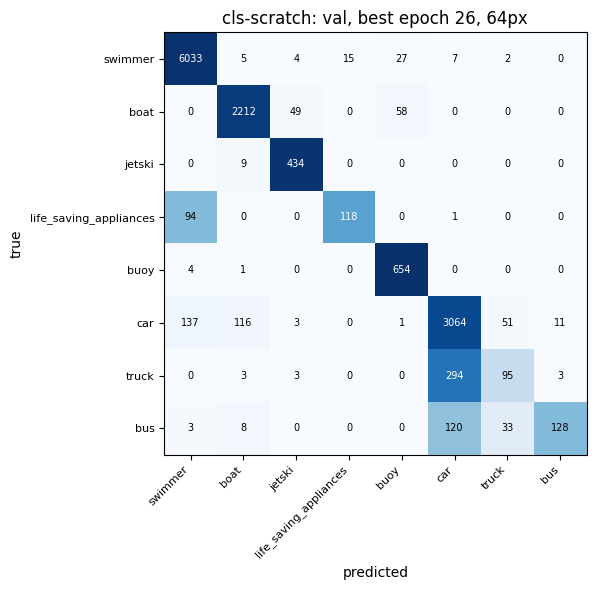

<Artifact cls-scratch-model>

In [10]:
ck = torch.load(CKPT, map_location=DEVICE); model.load_state_dict(ck['model'])
P, Y, vl = predict(val_dl); pred = P.argmax(1)
print(classification_report(Y, pred, labels=range(len(ac.CLASSES)), target_names=ac.CLASSES, digits=3, zero_division=0))
cm = confusion_matrix(Y, pred, labels=range(len(ac.CLASSES)))
cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(7, 6)); ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
for i in range(len(cm)):
    for j in range(len(cm)): ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=7, color='white' if cmn[i, j] > .5 else 'black')
ax.set_xticks(range(len(cm)), ac.CLASSES, rotation=45, ha='right', fontsize=8); ax.set_yticks(range(len(cm)), ac.CLASSES, fontsize=8)
ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title(f'{RUN}: val, best epoch {best_epoch}, {IMG}px'); plt.tight_layout()
cm_png = OUT_DIR / out_name(f'ValConfusion_{RUN}', 'png'); plt.savefig(cm_png, dpi=130); plt.show()

vp = val_index[['crop_id', 'dataset', 'category', 'source', 'box_side']].copy()
vp['pred'] = [ac.CLASSES[k] for k in pred]; vp['conf'] = P.max(1)
for i, c in enumerate(ac.CLASSES): vp[f'p_{c}'] = P[:, i].round(4)
vp.to_csv(OUT_DIR / out_name(f'ValPredictions_{RUN}', 'csv.gz'), index=False)

final = val_metrics(P, Y, vl)
wandb.log({'val/confusion_matrix': wandb.plot.confusion_matrix(y_true=Y, preds=pred, class_names=ac.CLASSES),
           'val/confusion_png': wandb.Image(str(cm_png))})
wandb.summary.update({'best_epoch': best_epoch, **{f'best/{k}': v for k, v in final.items()}})
art = wandb.Artifact(f'{RUN}-model', type='model', metadata={'val_macro_f1': best, 'epoch': best_epoch})
art.add_file(str(CKPT)); wb.log_artifact(art)

## 8. Learning curves and summary

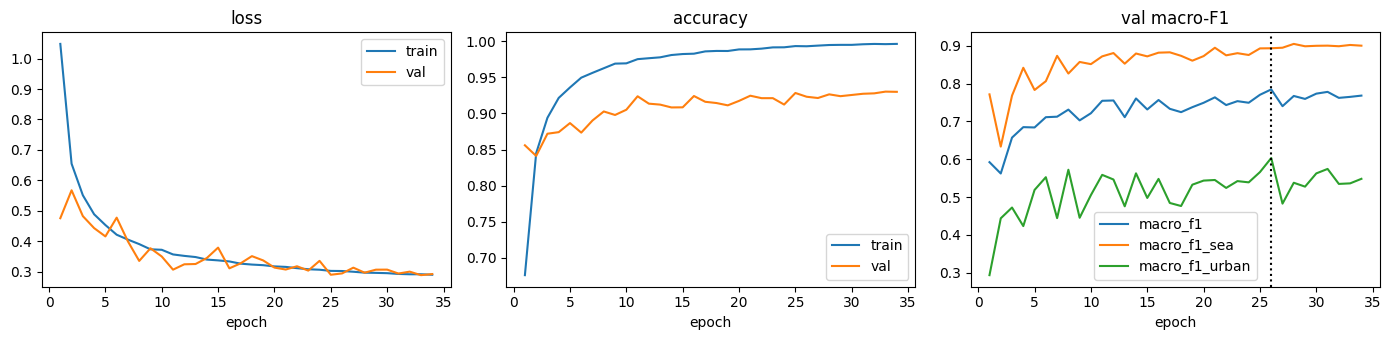

saved /content/drive/MyDrive/AI251P_Capstone_CrossDomainAerial/02_Classification/2026-10-21_Step5Summary_v1.json
{
 "wandb_url": "https://wandb.ai/mason-alharthi-king-abdullah-university-of-science-and-/ai251p-capstone/runs/3vl7thzl",
 "best_epoch": 26,
 "val_best": {
  "val/loss": 0.2937263774871826,
  "val/acc": 0.9230434782608695,
  "val/macro_f1": 0.7846419504104378,
  "val/macro_f1_sea": 0.8933995660852888,
  "val/macro_f1_urban": 0.6033792576190193,
  "val_recall/swimmer": 0.9901526341703595,
  "val_recall/boat": 0.9538594221647262,
  "val_recall/jetski": 0.9796839729119639,
  "val_recall/life_saving_appliances": 0.5539906103286385,
  "val_recall/buoy": 0.992412746585736,
  "val_recall/car": 0.9057049955660657,
  "val_recall/truck": 0.23869346733668342,
  "val_recall/bus": 0.4383561643835616
 }
}


epoch,▁▁▁▂▂▂▂▂▃▃▃▃▄▄▄▄▄▅▅▅▅▅▆▆▆▆▇▇▇▇▇████
epoch_time_s,▄▂▂▄▁▁▂▂▂▃▅▇█▆▆▅▇███▇███▇▆▅▅▃▃▃▂▂▁
lr,▄███████▇▇▇▇▇▆▆▆▅▅▅▅▄▄▄▃▃▃▃▂▂▂▂▁▁▁
train/acc,▁▅▆▆▇▇▇▇▇▇████████████████████████
train/loss,█▄▃▃▃▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val/acc,▂▁▃▄▅▄▅▆▅▆▇▇▇▆▆█▇▇▇▇█▇▇▇█▇▇███████
val/loss,▆█▆▅▄▆▄▂▃▃▁▂▂▂▃▂▂▃▂▂▁▂▁▂▁▁▂▁▁▁▁▁▁▁
val/macro_f1,▂▁▄▅▅▆▆▆▅▆▇▇▆▇▆▇▆▆▇▇▇▇▇▇██▇▇▇██▇▇▇
val/macro_f1_sea,▅▁▄▆▅▅▇▆▇▇▇▇▇▇▇▇▇▇▇▇█▇▇▇██████████
val/macro_f1_urban,▁▄▅▄▆▇▄▇▄▆▇▇▅▇▆▇▅▅▆▇▇▆▇▇▇█▅▇▆▇▇▆▆▇
+8,...


In [11]:
H = pd.DataFrame(history)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].plot(H.epoch, H['train/loss'], label='train'); ax[0].plot(H.epoch, H['val/loss'], label='val'); ax[0].set_title('loss'); ax[0].legend()
ax[1].plot(H.epoch, H['train/acc'], label='train'); ax[1].plot(H.epoch, H['val/acc'], label='val'); ax[1].set_title('accuracy'); ax[1].legend()
for k in ('val/macro_f1', 'val/macro_f1_sea', 'val/macro_f1_urban'): ax[2].plot(H.epoch, H[k], label=k.split('/')[1])
ax[2].axvline(best_epoch, color='k', ls=':'); ax[2].set_title('val macro-F1'); ax[2].legend()
for a in ax: a.set_xlabel('epoch')
plt.tight_layout(); plt.savefig(OUT_DIR / out_name(f'Curves_{RUN}', 'png'), dpi=120); plt.show()
H.to_csv(OUT_DIR / out_name(f'History_{RUN}', 'csv'), index=False)

SUMMARY = {'run': RUN, 'created': time.strftime('%Y-%m-%d %H:%M'), 'version': VERSION, 'wandb_url': wb.url,
           'config': CFG, 'crops_used': CROPS_USED, 'device': DEVICE, 'n_params': N_PARAMS, 'sanity_overfit': SANITY,
           'best_epoch': best_epoch, 'epochs_run': int(H.epoch.max()), 'checkpoint': CKPT.name,
           'val_best': final, 'test': 'not evaluated (Step 8)'}
out = OUT_DIR / out_name('Step5Summary', 'json')
json.dump(SUMMARY, open(out, 'w'), indent=2, default=float)
print('saved', out); print(json.dumps({k: SUMMARY[k] for k in ('wandb_url', 'best_epoch', 'val_best')}, indent=1, default=float))
wandb.finish()